# Predicting Credit Card Payment Default
## Deliverable 1
**Team:** Akshay Prabhu and Satya

This notebook reproduces the initial report using the UCI Default of Credit Card Clients dataset. Saved outputs were executed locally. Run all cells in Google Colab before capturing the required Colab screenshots.

**Research question:** Can repayment history and financial account attributes improve next month default prediction relative to a majority class baseline?

**Purpose:** Prioritize voluntary customer assistance and human review. This historical educational model is not validated for current lending decisions.

**Source:** Yeh, I. (2009). Default of Credit Card Clients. UCI. https://doi.org/10.24432/C55S3H

### Shared notebook
[Open the team's Google Colab notebook](https://colab.research.google.com/drive/1822K7WCL6zBHtPDmMaL5btEDFJEgvnGC?usp=sharing)

The saved outputs in this repository copy were generated locally. The shared Colab notebook also displays the initial results. Use the README for setup and interpretation.


In [1]:
# Install the Excel reader only if it is missing.
import importlib.util, subprocess, sys
if importlib.util.find_spec("xlrd") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "xlrd"])

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import urllib.request, zipfile, io

source = "https://archive.ics.uci.edu/static/public/350/default+of+credit+card+clients.zip"
workbook = Path("default of credit card clients.xls")
if not workbook.exists():
    try:
        with urllib.request.urlopen(source, timeout=60) as response:
            archive_bytes = response.read()
        with zipfile.ZipFile(io.BytesIO(archive_bytes)) as archive:
            member = next(n for n in archive.namelist() if n.endswith(".xls"))
            workbook.write_bytes(archive.read(member))
    except Exception:
        print("Automatic download failed. Upload the extracted UCI .xls workbook.")
        from google.colab import files
        files.upload()
df = pd.read_excel(workbook, header=1)
print("Loaded:", df.shape)


Loaded: (30000, 25)


## Data checks and feature selection
Planned lead: Akshay; peer review: Satya. Verify identifiers, repeated profiles, class balance, and monetary units. No undocumented outlier removal is performed.

In [2]:
target = "default payment next month"
y = df[target]
print("Rows and columns:", df.shape)
print("Missing cells:", df.isna().sum().sum())
print("Duplicate IDs:", df.ID.duplicated().sum())
print("Repeated records excluding ID:", df.drop(columns="ID").duplicated().sum())
print(pd.DataFrame({
    "count": y.value_counts().sort_index(),
    "proportion": y.value_counts(normalize=True).sort_index()
}))
excluded = ["ID", target, "SEX", "EDUCATION", "MARRIAGE", "AGE"]
X = df.drop(columns=excluded)
cat = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
num = [c for c in X if c not in cat]
print("Selected predictors:", len(X.columns))
print("Numeric:", num)
print("Categorical:", cat)
assert y.isin([0, 1]).all()
assert len(X.columns) == 19


Rows and columns: (30000, 25)
Missing cells: 0
Duplicate IDs: 0
Repeated records excluding ID: 35
                            count  proportion
default payment next month                   
0                           23364      0.7788
1                            6636      0.2212
Selected predictors: 19
Numeric: ['LIMIT_BAL', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']
Categorical: ['PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']


## Training split and exploratory analysis
Planned EDA lead: Satya; peer review: Akshay. The 80/20 split is stratified. Explore training data only to avoid using the test partition to guide feature choices.

Training: 24000 Test: 6000
Training default rate: 0.22120833333333334
Training medians in New Taiwan dollars:
LIMIT_BAL    140000.0
BILL_AMT1     22330.0
PAY_AMT1       2100.5
dtype: float64


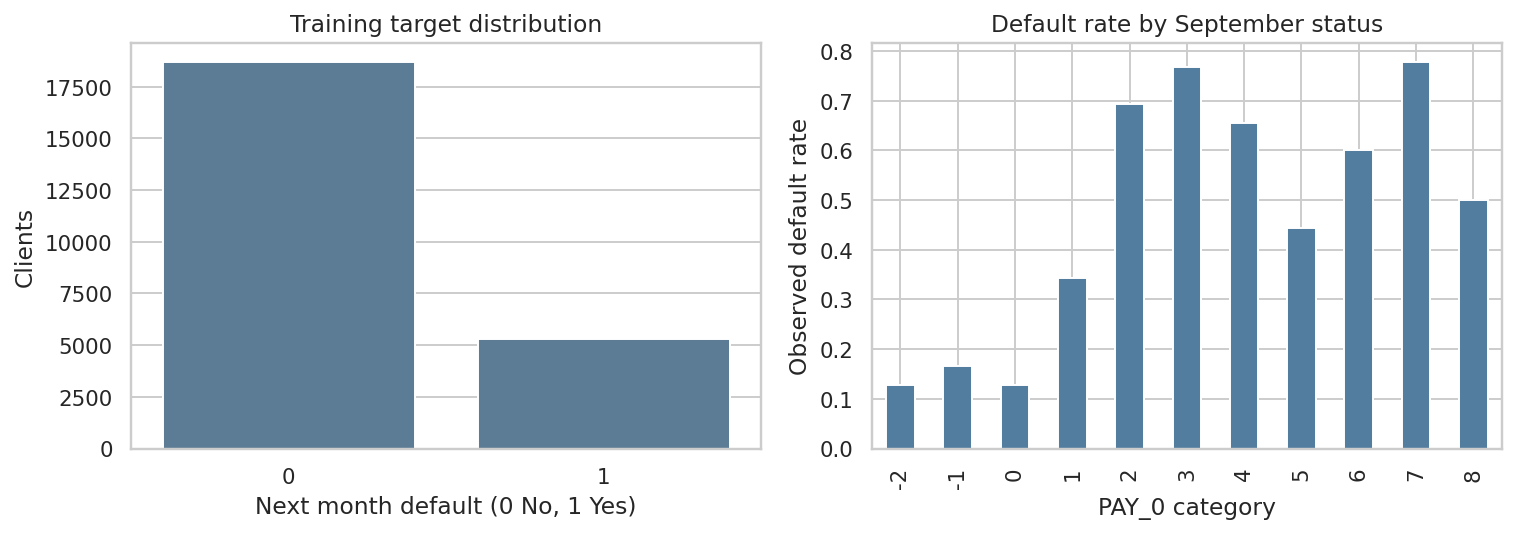

In [3]:
from sklearn.model_selection import train_test_split
tr, te = train_test_split(
    np.arange(len(df)), test_size=0.2, stratify=y, random_state=42
)
print("Training:", len(tr), "Test:", len(te))
print("Training default rate:", y.iloc[tr].mean())
print("Training medians in New Taiwan dollars:")
print(df.iloc[tr][["LIMIT_BAL", "BILL_AMT1", "PAY_AMT1"]].median())
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(x=y.iloc[tr], ax=axes[0], color="#527d9f")
axes[0].set(
    title="Training target distribution",
    xlabel="Next month default (0 No, 1 Yes)", ylabel="Clients"
)
rates = pd.DataFrame({
    "Status": df.iloc[tr].PAY_0, "Default": y.iloc[tr]
}).groupby("Status").Default.mean()
rates.plot.bar(ax=axes[1], color="#527d9f")
axes[1].set(
    title="Default rate by September status",
    xlabel="PAY_0 category", ylabel="Observed default rate"
)
fig.tight_layout()
plt.show()


## Preprocessing pipeline
Planned ownership: Akshay handles numeric scaling; Satya handles categorical encoding. Both review leakage prevention.

Keep the 35 repeated profiles because distinct IDs may represent different people; investigate profile grouping in Deliverable 2. Keep negative bill amounts because they may represent credits. Exclude demographic variables from prediction, retain them separately for later fairness auditing. Exclusion alone does not remove bias. Fit imputation, scaling, and encoding using training data only.


In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
numeric = make_pipeline(
    SimpleImputer(strategy="median"), StandardScaler()
)
categorical = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    OneHotEncoder(handle_unknown="ignore")
)
prep = ColumnTransformer([
    ("numeric", numeric, num), ("status", categorical, cat)
])
print(prep)


ColumnTransformer(transformers=[('numeric',
                                 Pipeline(steps=[('simpleimputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('standardscaler',
                                                  StandardScaler())]),
                                 ['LIMIT_BAL', 'BILL_AMT1', 'BILL_AMT2',
                                  'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5',
                                  'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2',
                                  'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5',
                                  'PAY_AMT6']),
                                ('status',
                                 Pipeline(steps=[('simpleimputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehotencoder',
                                                  OneHotEncod

## Initial model and baseline
Planned model lead: Akshay; metrics lead: Satya. Use default L2 regularization, C=1, no class weighting, and threshold 0.50. No model tuning has been performed.

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
model = make_pipeline(
    prep, LogisticRegression(C=1.0, max_iter=2000, random_state=42)
)
model.fit(X.iloc[tr], y.iloc[tr])
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X.iloc[tr], y.iloc[tr])
print("Training complete; all transformations fitted on training data.")
print("Classification threshold: 0.50")


Training complete; all transformations fitted on training data.
Classification threshold: 0.50


                     Accuracy  Precision   Recall       F1  ROC AUC
Logistic regression  0.815833   0.657670 0.348907 0.455933 0.754422
Majority baseline    0.778833   0.000000 0.000000 0.000000 0.500000
Confusion matrix, rows actual and columns predicted:
[[4432  241]
 [ 864  463]]


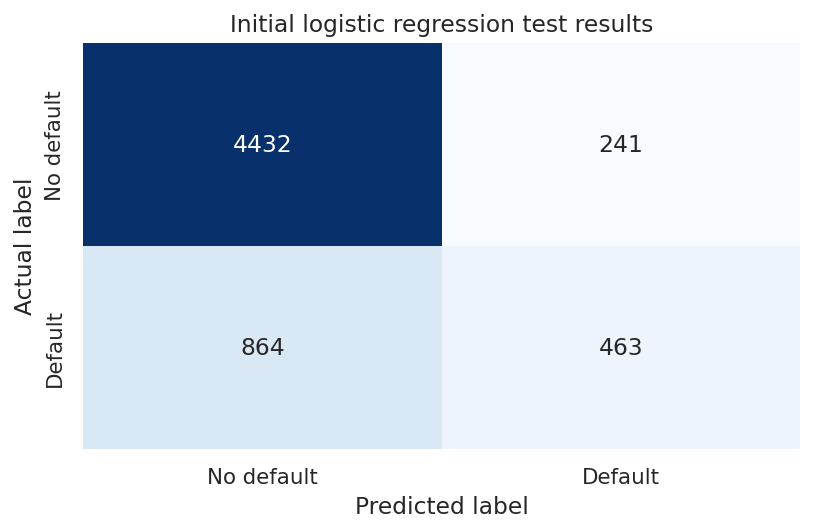

In [6]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix
)
def evaluate(fitted):
    predictions = fitted.predict(X.iloc[te])
    probabilities = fitted.predict_proba(X.iloc[te])[:, 1]
    actual = y.iloc[te]
    return {
        "Accuracy": accuracy_score(actual, predictions),
        "Precision": precision_score(actual, predictions, zero_division=0),
        "Recall": recall_score(actual, predictions, zero_division=0),
        "F1": f1_score(actual, predictions, zero_division=0),
        "ROC AUC": roc_auc_score(actual, probabilities)
    }
results = pd.DataFrame({
    "Logistic regression": evaluate(model),
    "Majority baseline": evaluate(baseline)
}).T
print(results.to_string(float_format=lambda n: f"{n:.6f}"))
matrix = confusion_matrix(y.iloc[te], model.predict(X.iloc[te]))
print("Confusion matrix, rows actual and columns predicted:", matrix, sep="\n")
fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(
    matrix, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
    xticklabels=["No default", "Default"],
    yticklabels=["No default", "Default"]
)
ax.set(
    title="Initial logistic regression test results",
    xlabel="Predicted label", ylabel="Actual label"
)
fig.tight_layout()
plt.show()


## Interpretation and next iteration
The initial local run gives 81.58% accuracy, 65.77% precision, 34.89% recall, F1 45.59%, and ROC AUC 0.7544. The majority baseline gives 77.88% accuracy and zero default recall. The confusion matrix has 4,432 true negatives, 241 false positives, 864 false negatives, and 463 true positives. Rerunning in Colab should reproduce these values, subject to library versions and numerical tolerances.

Low default recall means many people needing assistance are missed. Accuracy alone would obscure this limitation. Historical associations do not establish causation or suitability for current customers.

For Deliverable 2, tune regularization, class weights, and thresholds using cross-validation within training data. Evaluate calibration, precision recall AUC, and subgroup error rates. Do not repeatedly select models against the already inspected test set. Consider a grouped profile sensitivity check for repeated profiles.

## Ethics
Use public anonymized data only. Avoid publishing personal customer data, credentials, or institutional data. Assess proxy discrimination even when demographics are excluded from prediction. Keep human review and an appeal route. Validate on current representative data before considering use outside this class.

## Environment


In [7]:
import sklearn, matplotlib
print("Python:", sys.version.split()[0])
for name, version in [
    ("pandas", pd.__version__), ("NumPy", np.__version__),
    ("scikit-learn", sklearn.__version__),
    ("Matplotlib", matplotlib.__version__), ("Seaborn", sns.__version__)
]:
    print(name, version)


Python: 3.12.14
pandas 2.2.3
NumPy 2.3.5
scikit-learn 1.8.0
Matplotlib 3.10.8
Seaborn 0.13.2
